# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import numpy as np
import pandas as pd

brut = pd.read_csv("donnees/consommation_brut.csv")
brut.shape, brut.dtypes, brut.isna().sum(), brut.duplicated().sum()

((300, 4),
 mois                  str
 quartier              str
 kwh                   str
 heures_courant    float64
 dtype: object,
 mois              0
 quartier          0
 kwh               9
 heures_courant    0
 dtype: int64,
 np.int64(12))

**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
brut["quartier"].nunique()

43

**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
non_convertissable = pd.to_numeric(brut["kwh"], errors="coerce").isna()
brut[non_convertissable]["kwh"]
#TO DO

0      184410 kWh
4      206280 kWh
9      215140 kWh
13        251 900
21     274520 kWh
          ...    
273       104 640
277    166700 kWh
284        73 110
292       171 160
297    187230 kWh
Name: kwh, Length: 61, dtype: str

## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = propre["kwh"].str.replace(" kWh", "").str.replace(" ", "").str.strip()
propre["kwh"] = pd.to_numeric(propre["kwh"], errors="coerce")
propre.isna().sum()

mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64

**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
brut["quartier"].unique()
propre["quartier"] = propre["quartier"].str.strip().str.title()
propre["quartier"] = propre["quartier"].str.replace("Bas-Peu-De-Chose", "Bas-Peu-de-Chose").str.replace("Centre-Ville", "Centre-ville")
propre["quartier"].nunique()

12

**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset="kwh")
propre.shape

(279, 4)

**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
for quartier in propre["quartier"].unique():
    de_quartier = propre["quartier"] == quartier
    mediane = propre.loc[de_quartier, "kwh"].median()
    suspect = (de_quartier) & (propre["kwh"] > 3*mediane)
    propre.loc[suspect, "kwh"] = propre.loc[suspect, "kwh"] / 10

propre["kwh"].max()

np.float64(742780.0)

**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
propre.shape

(279, 4)

In [9]:
pd.read_csv("donnees/consommation.csv").shape

(288, 5)

In [10]:
pd.read_csv("donnees/consommation.csv").equals(propre)

False

In [11]:
reference = pd.read_csv("donnees/consommation.csv")
reference = reference[
    reference.set_index(["mois", "quartier"]).index.isin(
        propre.set_index(["mois", "quartier"]).index
    )
]
reference.equals(propre)

False

In [12]:
propre.tail(40)

,mois,quartier,kwh,heures_courant
259,2024-09,Rue 15,153430.0,7.9
260,2024-10,Rue 15,163010.0,8.3
261,2024-11,Rue 15,185660.0,9.8
262,2024-12,Rue 15,235210.0,11.2
263,2025-01,Rue 15,190440.0,10.1
264,2025-02,Rue 15,198720.0,11.1
265,2025-03,Rue 15,199900.0,10.2
266,2025-04,Rue 15,241720.0,13.0
267,2025-05,Rue 15,303180.0,14.7
268,2025-06,Rue 15,254750.0,11.2


In [13]:
pd.read_csv("donnees/consommation.csv").eq(propre).tail(25)

,commune,heures_courant,kwh,mois,quartier
275,False,False,False,False,True
276,False,False,False,False,True
277,False,False,False,False,True
278,False,False,False,False,True
279,False,False,False,False,True
280,False,False,False,False,True
281,False,False,False,False,True
282,False,False,False,False,True
283,False,False,False,False,False
284,False,False,False,False,True


In [14]:
reference = pd.read_csv("donnees/consommation.csv")
colonnes = propre.columns.tolist()

reference = reference[
    reference.set_index(["mois", "quartier"]).index.isin(
        propre.set_index(["mois", "quartier"]).index
    )
]

propre_compare = propre[colonnes].sort_values(
    ["mois", "quartier"]
).reset_index(drop=True)

reference = reference[colonnes].sort_values(
    ["mois", "quartier"]
).reset_index(drop=True)

propre_compare["kwh"] = propre_compare["kwh"].astype(int)

propre_compare.equals(reference)

True

Quelque chose cloche avec la verification
Ca donne faux pour une raison quelconque (supposement le nombre d'elements, car on dirait que consommation.csv a + d'elements et une colonne en + que le dataframe de base)

## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [15]:
fusion_propre_quartiers = propre.merge(pd.read_csv("donnees/quartiers.csv"), on="quartier", how="inner")
fusion_propre_quartiers["kwh_par_abonne"] = (fusion_propre_quartiers["kwh"] / fusion_propre_quartiers["abonnes"]).round(1)
fusion_propre_quartiers["annee"] = pd.to_datetime(fusion_propre_quartiers["mois"]).dt.year
fusion_propre_quartiers

,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024
1,2024-02,Bas-Peu-de-Chose,195930.0,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024
2,2024-03,Bas-Peu-de-Chose,186560.0,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024
3,2024-04,Bas-Peu-de-Chose,236730.0,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024
4,2024-05,Bas-Peu-de-Chose,206280.0,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024
...,...,...,...,...,...,...,...,...,...
274,2025-08,Petite-Anse,159780.0,12.0,Cap-Haïtien,Résidentiel,1890,84.5,2025
275,2025-09,Petite-Anse,171060.0,12.5,Cap-Haïtien,Résidentiel,1890,90.5,2025
276,2025-10,Petite-Anse,187230.0,14.7,Cap-Haïtien,Résidentiel,1890,99.1,2025
277,2025-11,Petite-Anse,101850.0,8.4,Cap-Haïtien,Résidentiel,1890,53.9,2025


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [16]:
avec_meteo = fusion_propre_quartiers.merge(pd.read_csv("donnees/meteo.csv"), on=["mois", "commune"], how="inner")

avec_meteo.shape[0], avec_meteo["temperature_c"].isna().sum().sum()

(279, np.int64(0))

In [17]:
avec_meteo

,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee,temperature_c,pluie_mm
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024,25.7,33
1,2024-02,Bas-Peu-de-Chose,195930.0,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024,25.5,40
2,2024-03,Bas-Peu-de-Chose,186560.0,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024,27.2,99
3,2024-04,Bas-Peu-de-Chose,236730.0,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024,27.4,119
4,2024-05,Bas-Peu-de-Chose,206280.0,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024,28.1,185
...,...,...,...,...,...,...,...,...,...,...,...
274,2025-08,Petite-Anse,159780.0,12.0,Cap-Haïtien,Résidentiel,1890,84.5,2025,28.5,232
275,2025-09,Petite-Anse,171060.0,12.5,Cap-Haïtien,Résidentiel,1890,90.5,2025,29.1,179
276,2025-10,Petite-Anse,187230.0,14.7,Cap-Haïtien,Résidentiel,1890,99.1,2025,27.8,219
277,2025-11,Petite-Anse,101850.0,8.4,Cap-Haïtien,Résidentiel,1890,53.9,2025,26.1,133


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [18]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)

In [19]:
test_lecture = pd.read_csv("donnees/consommation_propre.csv")
test_lecture.shape

(279, 11)

## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [20]:
avec_meteo.groupby("type")["kwh_par_abonne"].mean().round(1)

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64

In [21]:
avec_meteo.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False)

quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64

**Ce qu'on en conclut :**

#To Write

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

In [22]:
conso_commune_annee = avec_meteo.pivot_table(index=["commune"], columns="annee", values="kwh", aggfunc="sum")
conso_commune_annee

annee,2024,2025
commune,,
Cap-Haïtien,4587550.0,5617740.0
Delmas,11613360.0,11741410.0
Port-au-Prince,10085070.0,10313770.0
Pétion-Ville,8595330.0,9675080.0


In [23]:
conso_commune_annee["hausse_%"] = ((conso_commune_annee[2025] / conso_commune_annee[2024] - 1) * 100)
conso_commune_annee["hausse_%"] = conso_commune_annee["hausse_%"].round(1)
conso_commune_annee

annee,2024,2025,hausse_%
commune,,,
Cap-Haïtien,4587550.0,5617740.0,22.5
Delmas,11613360.0,11741410.0,1.1
Port-au-Prince,10085070.0,10313770.0,2.3
Pétion-Ville,8595330.0,9675080.0,12.6


In [24]:
conso_commune_annee[[2024, 2025]] = conso_commune_annee[[2024, 2025]] / 1000000
conso_commune_annee[[2024, 2025]] = conso_commune_annee[[2024, 2025]].round(2)
conso_commune_annee

annee,2024,2025,hausse_%
commune,,,
Cap-Haïtien,4.59,5.62,22.5
Delmas,11.61,11.74,1.1
Port-au-Prince,10.09,10.31,2.3
Pétion-Ville,8.60,9.68,12.6


In [25]:
conso_commune_mois = avec_meteo.pivot_table(index="mois", columns="commune", values="kwh_par_abonne")
conso_commune_mois

commune,Cap-Haïtien,Delmas,Port-au-Prince,Pétion-Ville
mois,,,,
2024-01,76.333333,179.433333,224.933333,180.066667
2024-02,86.333333,182.566667,222.700000,240.133333
2024-03,116.166667,171.833333,227.933333,240.566667
2024-04,78.950000,196.600000,182.633333,242.066667
2024-05,115.866667,239.666667,236.833333,251.033333
2024-06,96.966667,163.866667,249.733333,258.466667
2024-07,136.633333,226.866667,205.533333,247.333333
2024-08,155.500000,196.800000,237.950000,254.166667
2024-09,107.800000,206.233333,211.366667,284.633333


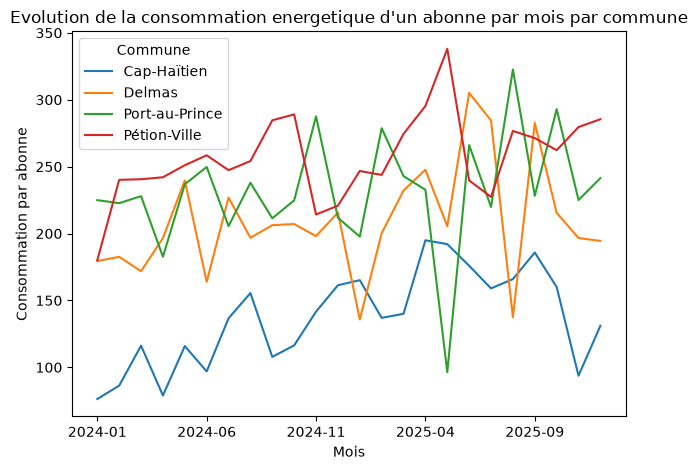

In [26]:
import matplotlib as mp
import matplotlib.pyplot as plt

courbe_conso = conso_commune_mois.plot(kind="line")
courbe_conso.set_title("Evolution de la consommation energetique d'un abonne par mois par commune")
courbe_conso.set_xlabel("Mois")
courbe_conso.set_ylabel("Consommation par abonne")
courbe_conso.legend(title="Commune")
plt.tight_layout()
plt.savefig("evolution_conso_abonne_commune_mois.png", dpi=120)
plt.show()

**Ce qu'on en conclut :**

To Be Written

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

In [27]:
avec_meteo_residentiel = avec_meteo[avec_meteo["type"] == "Résidentiel"]
avec_meteo_residentiel

,mois,quartier,kwh,heures_courant,commune,type,abonnes,kwh_par_abonne,annee,temperature_c,pluie_mm
0,2024-01,Bas-Peu-de-Chose,184410.0,10.6,Port-au-Prince,Résidentiel,2150,85.8,2024,25.7,33
1,2024-02,Bas-Peu-de-Chose,195930.0,11.9,Port-au-Prince,Résidentiel,2150,91.1,2024,25.5,40
2,2024-03,Bas-Peu-de-Chose,186560.0,10.2,Port-au-Prince,Résidentiel,2150,86.8,2024,27.2,99
3,2024-04,Bas-Peu-de-Chose,236730.0,12.2,Port-au-Prince,Résidentiel,2150,110.1,2024,27.4,119
4,2024-05,Bas-Peu-de-Chose,206280.0,10.2,Port-au-Prince,Résidentiel,2150,95.9,2024,28.1,185
...,...,...,...,...,...,...,...,...,...,...,...
274,2025-08,Petite-Anse,159780.0,12.0,Cap-Haïtien,Résidentiel,1890,84.5,2025,28.5,232
275,2025-09,Petite-Anse,171060.0,12.5,Cap-Haïtien,Résidentiel,1890,90.5,2025,29.1,179
276,2025-10,Petite-Anse,187230.0,14.7,Cap-Haïtien,Résidentiel,1890,99.1,2025,27.8,219
277,2025-11,Petite-Anse,101850.0,8.4,Cap-Haïtien,Résidentiel,1890,53.9,2025,26.1,133


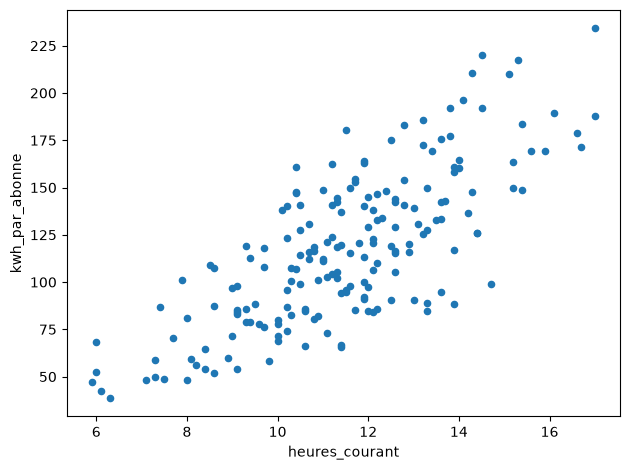

In [28]:
courbe_heure_conso = avec_meteo_residentiel.plot(kind="scatter", x="heures_courant", y="kwh_par_abonne")
courbe_conso.set_title("Evolution de la consommation energetique d'un abonne par mois par commune")
courbe_conso.set_xlabel("Mois")
courbe_conso.set_ylabel("Consommation par abonne")
courbe_conso.legend(title="Commune")
plt.tight_layout()
plt.savefig("evolution_conso_abonne_commune_mois.png", dpi=120)
plt.show()

Correlation avec les heures courant

In [29]:
avec_meteo_residentiel["kwh_par_abonne"].corr(avec_meteo_residentiel["heures_courant"]).round(2)

np.float64(0.76)

Correlation avec la temperature

In [30]:
avec_meteo_residentiel["kwh_par_abonne"].corr(avec_meteo_residentiel["temperature_c"]).round(2)

np.float64(-0.15)

**Ce qu'on en conclut :**

TO BE WRITTEN

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

In [58]:
heure_median_commune = avec_meteo.groupby("commune")["heures_courant"]

Median = heure_median_commune.median()
Q1 = heure_median_commune.quantile(0.25)
Q3 = heure_median_commune.quantile(0.75)

rapport = pd.DataFrame({"Mediane" : Median, "Q1" : Q1, "Q3" : Q3})

rapport

,Mediane,Q1,Q3
commune,,,
Cap-Haïtien,10.0,8.3,11.70
Delmas,11.9,10.1,13.00
Port-au-Prince,11.6,10.7,13.10
Pétion-Ville,11.6,10.4,13.05


In [61]:
cap_infos = avec_meteo[avec_meteo["commune"] == "Cap-Haïtien"][["mois", "heures_courant"]]
cap_infos

,mois,heures_courant
210,2024-01,6.1
211,2024-02,7.3
212,2024-03,8.1
213,2024-04,11.7
214,2024-05,5.9
...,...,...
274,2025-08,12.0
275,2025-09,12.5
276,2025-10,14.7
277,2025-11,8.4


Text(0, 0.5, 'Heures Courant')

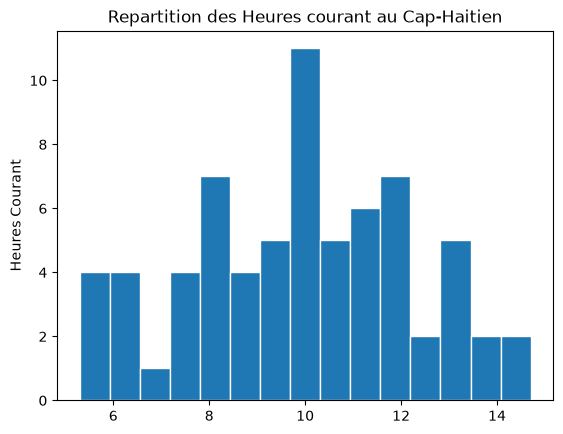

In [ ]:
cap_graphe = cap_infos["heures_courant"].plot(kind="hist", edgecolor="white", bins=15, title="Repartition des Heures courant au Cap-Haitien")
cap_graphe.set_ylabel("Heures Courant")
cap_graphe.set

In [99]:
# releves_2025 = avec_meteo[avec_meteo["mois"].dt.year == 2025]
# releves_2025
copy_avec_meteo = avec_meteo.copy()
copy_avec_meteo["mois"] = pd.to_datetime(copy_avec_meteo["mois"])
copy_avec_meteo[(copy_avec_meteo["mois"].dt.year == 2025) & (copy_avec_meteo["heures_courant"] < 8)][["mois", "heures_courant", "quartier"]]

,mois,heures_courant,quartier
81,2025-01-01,7.4,Delmas 33
227,2025-08-01,7.3,Carénage
253,2025-11-01,5.9,Rue 15


**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [31]:
avec_meteo.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]]

,mois,quartier,type,kwh
87,2025-07,Delmas 33,Commercial,742780.0
56,2024-11,Centre-ville,Commercial,597730.0
88,2025-09,Delmas 33,Commercial,591420.0


**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.